# Experiment 9: Principal Component Analysis (PCA)

## Aim
To perform dimensionality reduction using Principal Component Analysis (PCA) on the Student Performance dataset.

## Learning Outcomes
After completing this experiment, students will be able to:

1. Select suitable numerical features for PCA.
2. Standardize features before applying PCA.
3. Calculate explained variance and choose an appropriate number of components.
4. Transform high-dimensional data into principal components.
5. Visualize students in two-dimensional PCA space.
6. Interpret component loadings and the information retained after reduction.

> **Important:** PCA is an **unsupervised dimensionality-reduction technique**. The target `pass_fail` is not used to create the components; it is used only to colour the final visualization.

## 1. Import Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Dataset

Keep the Student Performance CSV file in the same folder as the notebook when working locally. The Kaggle path used in the earlier experiments is included below.

In [2]:
possible_paths = [
    "/kaggle/input/datasets/tahreemrashid/student-performance-dataset/student_performance.csv",
    "student_performance.csv",
    "./data/student_performance.csv"
]

DATA_PATH = next((path for path in possible_paths if os.path.exists(path)), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Download/upload student_performance.csv and update possible_paths."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully from:", DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully from: /kaggle/input/datasets/tahreemrashid/student-performance-dataset/student_performance.csv
Dataset shape: (1000, 15)


,student_id,name,gender,age,class,teacher_id,subject,test1_score,test2_score,final_exam_score,final_grade_letter,attendance_percentage,study_hours_per_week,assignments_submitted,pass_fail
0,1,Carson Rivera,Female,14,9th,105,Math,23.5,40.5,50.5,F,70.2,3.1,56.7,0
1,2,Ashley Walters,Male,15,10th,107,Computer,77.7,80.6,82.3,B,85.3,6.9,81.0,1
2,3,Linda Robinson,Male,15,10th,103,English,75.0,73.4,64.5,C,83.1,4.3,66.3,1
3,4,Brandon James,Female,17,11th,117,Computer,46.7,53.1,51.2,F,74.1,0.4,44.9,0
4,5,Helen Grant,Female,16,10th,112,Science,38.0,57.3,47.6,F,73.8,1.4,49.9,0


## 3. Understand the Dataset

Before applying PCA, inspect the data types and missing values. PCA requires numerical values and cannot directly handle missing observations.

In [3]:
display(pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum(),
    "Unique Values": df.nunique()
}))

,Column,Data Type,Missing Values,Unique Values
student_id,student_id,int64,0,1000
name,name,object,0,1000
gender,gender,object,0,2
age,age,int64,0,5
class,class,object,0,4
teacher_id,teacher_id,int64,0,20
subject,subject,object,0,6
test1_score,test1_score,float64,0,481
test2_score,test2_score,float64,0,471
final_exam_score,final_exam_score,float64,0,481


## 4. Select Features for PCA

For this experiment we use the meaningful numerical student-performance measurements:

- `age`
- `test1_score`
- `test2_score`
- `final_exam_score`
- `attendance_percentage`
- `study_hours_per_week`
- `assignments_submitted`

Identifiers such as `student_id` and `teacher_id` are excluded because they do not describe academic performance. `pass_fail` is excluded because it is the target label. `final_grade_letter` is also excluded because it is derived from final performance and would leak outcome information.

In [4]:
target_column = "pass_fail"

feature_columns = [
    "age",
    "test1_score",
    "test2_score",
    "final_exam_score",
    "attendance_percentage",
    "study_hours_per_week",
    "assignments_submitted"
]

# Keep only columns available in the dataset, and report any mismatch clearly.
missing_features = [col for col in feature_columns if col not in df.columns]
if missing_features:
    raise ValueError(f"Expected feature columns not found: {missing_features}")

X = df[feature_columns].copy()
y = df[target_column].copy() if target_column in df.columns else None

print("Features selected for PCA:")
print(feature_columns)
print("\nFeature matrix shape:", X.shape)
display(X.head())

Features selected for PCA:
['age', 'test1_score', 'test2_score', 'final_exam_score', 'attendance_percentage', 'study_hours_per_week', 'assignments_submitted']

Feature matrix shape: (1000, 7)


,age,test1_score,test2_score,final_exam_score,attendance_percentage,study_hours_per_week,assignments_submitted
0,14,23.5,40.5,50.5,70.2,3.1,56.7
1,15,77.7,80.6,82.3,85.3,6.9,81.0
2,15,75.0,73.4,64.5,83.1,4.3,66.3
3,17,46.7,53.1,51.2,74.1,0.4,44.9
4,16,38.0,57.3,47.6,73.8,1.4,49.9


## 5. Handle Missing Values

We use **median imputation**. The median is less sensitive to extreme values than the mean.

In [5]:
print("Missing values before imputation:")
display(X.isnull().sum().to_frame("Missing Values"))

imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=feature_columns,
    index=X.index
)

print("Total missing values after imputation:", int(X_imputed.isnull().sum().sum()))

Missing values before imputation:


,Missing Values
age,0
test1_score,0
test2_score,0
final_exam_score,0
attendance_percentage,0
study_hours_per_week,0
assignments_submitted,0


Total missing values after imputation: 0


## 6. Standardize the Features

PCA is distance- and variance-sensitive. Features such as marks (0–100) and age (approximately 15–20) have different ranges. Therefore, we standardize each feature to mean 0 and standard deviation 1.

$$z = 
rac{x - \mu}{\sigma}$$

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_columns, index=X.index)

print("Means after scaling (approximately 0):")
display(X_scaled_df.mean().round(3).to_frame("Mean"))

print("Standard deviations after scaling (approximately 1):")
display(X_scaled_df.std(ddof=0).round(3).to_frame("Standard Deviation"))

Means after scaling (approximately 0):


,Mean
age,0.0
test1_score,-0.0
test2_score,-0.0
final_exam_score,-0.0
attendance_percentage,-0.0
study_hours_per_week,0.0
assignments_submitted,0.0


Standard deviations after scaling (approximately 1):


,Standard Deviation
age,1.0
test1_score,1.0
test2_score,1.0
final_exam_score,1.0
attendance_percentage,1.0
study_hours_per_week,1.0
assignments_submitted,1.0


## 7. Apply PCA to All Components

Initially, PCA is fitted with all available components. This lets us examine how much variance is explained by each principal component.

In [8]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

variance_table = pd.DataFrame({
    "Principal Component": [f"PC{i}" for i in range(1, len(explained_variance) + 1)],
    "Explained Variance Ratio": explained_variance,
    "Explained Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

display(variance_table.round(2))

,Principal Component,Explained Variance Ratio,Explained Variance (%),Cumulative Variance (%)
0,PC1,0.65,65.19,65.19
1,PC2,0.14,14.29,79.48
2,PC3,0.08,8.05,87.53
3,PC4,0.04,4.16,91.69
4,PC5,0.03,3.34,95.04
5,PC6,0.03,2.57,97.60
6,PC7,0.02,2.40,100.00


## 8. Scree Plot and Cumulative Explained Variance

- A **scree plot** shows the variance explained by each component.
- The cumulative curve helps choose the smallest number of components that retains a desired amount of information, commonly 90% or 95%.

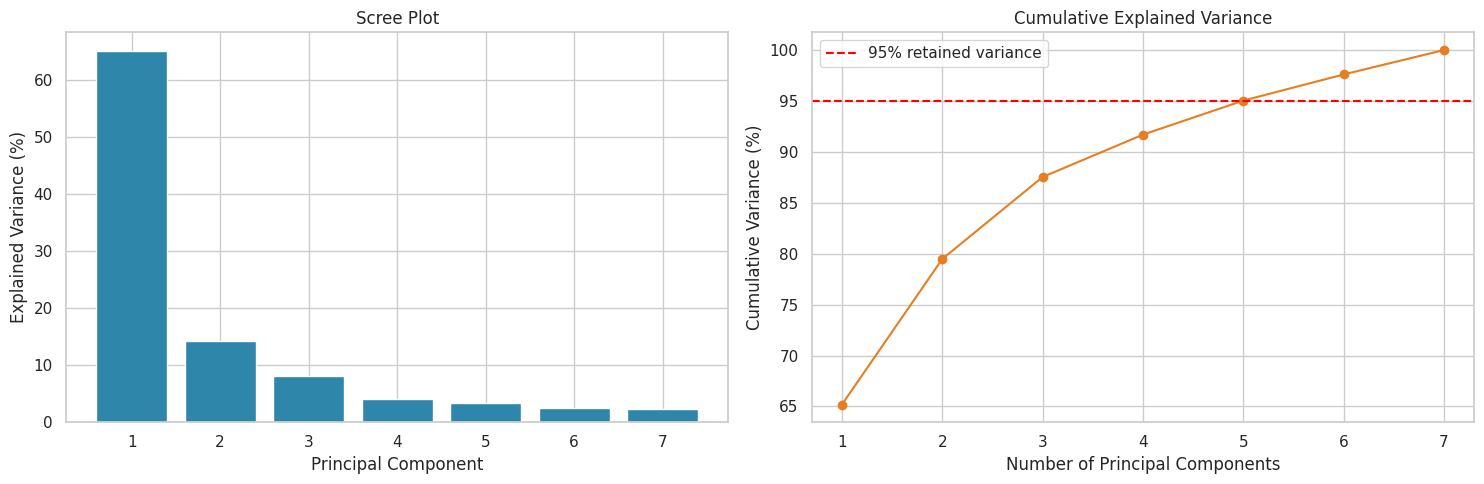

In [9]:
component_numbers = np.arange(1, len(explained_variance) + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(component_numbers, explained_variance * 100, color="#2E86AB")
axes[0].set_title("Scree Plot")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance (%)")
axes[0].set_xticks(component_numbers)

axes[1].plot(component_numbers, cumulative_variance * 100, marker="o", color="#E67E22")
axes[1].axhline(95, color="red", linestyle="--", label="95% retained variance")
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of Principal Components")
axes[1].set_ylabel("Cumulative Variance (%)")
axes[1].set_xticks(component_numbers)
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Choose the Number of Components

The following code finds the minimum number of principal components required to retain at least **95%** of the total variance.

In [10]:
variance_threshold = 0.95
n_components_95 = np.argmax(cumulative_variance >= variance_threshold) + 1

print(f"Components required to retain at least {variance_threshold:.0%} variance: {n_components_95}")
print(f"Variance retained: {cumulative_variance[n_components_95 - 1]:.2%}")

Components required to retain at least 95% variance: 5
Variance retained: 95.04%


## 10. Transform Data Using PCA

We create a reduced dataset with the number of components selected above. The principal components are new variables formed as weighted combinations of the original standardized features.

In [11]:
pca_reduced = PCA(n_components=n_components_95)
X_pca_reduced = pca_reduced.fit_transform(X_scaled)

pca_columns = [f"PC{i}" for i in range(1, n_components_95 + 1)]
pca_df = pd.DataFrame(X_pca_reduced, columns=pca_columns, index=X.index)

if y is not None:
    pca_df[target_column] = y.values

print("Original feature matrix shape:", X_scaled.shape)
print("Reduced PCA matrix shape:", X_pca_reduced.shape)
display(pca_df.head())

Original feature matrix shape: (1000, 7)
Reduced PCA matrix shape: (1000, 5)


,PC1,PC2,PC3,PC4,PC5,pass_fail
0,-3.604909,-1.475279,0.347568,1.172029,0.887932,0
1,2.146711,-0.762916,-0.286544,0.352768,0.070021,1
2,0.393307,-0.731843,-0.354562,-0.210603,-0.714914,1
3,-3.121867,0.981339,-0.439309,-0.560639,-0.228933,0
4,-3.058181,0.162556,-0.139880,0.035860,-0.242391,0


## 11. Two-Dimensional PCA Visualization

For visualization, we fit PCA with two components. The points are coloured using the original `pass_fail` label only to see whether pass/fail groups show a visible pattern in the reduced space.

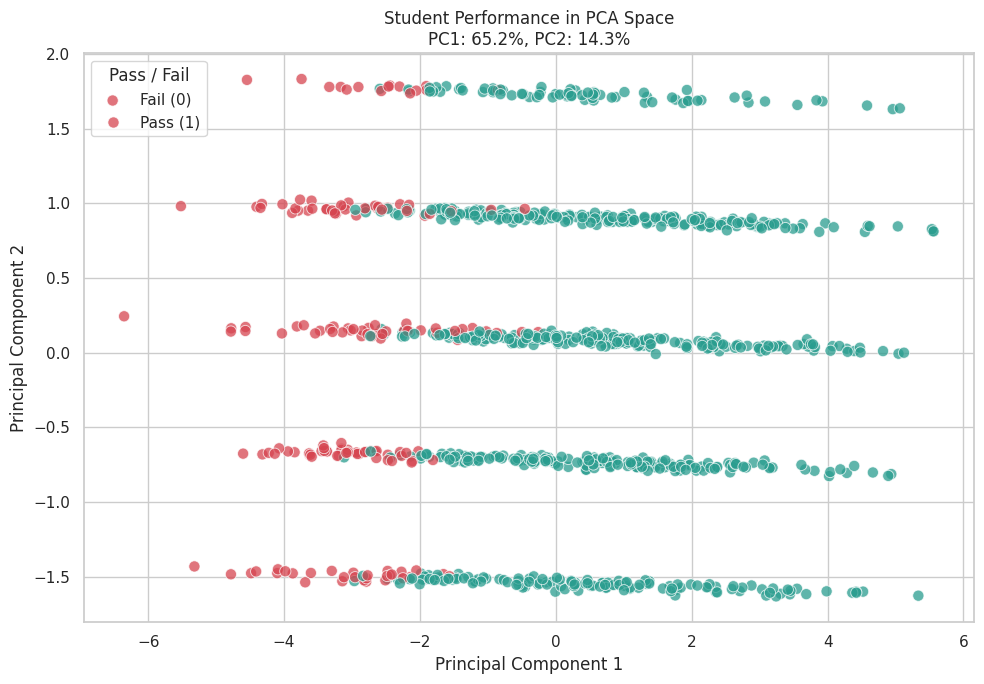

In [12]:
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

pca_2d_df = pd.DataFrame(X_pca_2d, columns=["PC1", "PC2"], index=X.index)
if y is not None:
    pca_2d_df[target_column] = y.values

plt.figure(figsize=(10, 7))
if y is not None:
    sns.scatterplot(
        data=pca_2d_df,
        x="PC1", y="PC2", hue=target_column,
        palette={0: "#D64550", 1: "#2A9D8F"}, alpha=0.75, s=65
    )
    plt.legend(title="Pass / Fail", labels=["Fail (0)", "Pass (1)"])
else:
    sns.scatterplot(data=pca_2d_df, x="PC1", y="PC2", alpha=0.75, s=65)

plt.title(
    f"Student Performance in PCA Space\n"
    f"PC1: {pca_2d.explained_variance_ratio_[0]:.1%}, "
    f"PC2: {pca_2d.explained_variance_ratio_[1]:.1%}"
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

## 12. Interpret PCA Loadings

Loadings show how strongly each original feature contributes to a principal component.

- Large positive or negative values mean the feature has a strong influence.
- The sign (+ or −) shows direction, not importance by itself.

Feature loadings for the first two principal components:


,PC1,PC2
age,0.016,0.999
test1_score,0.421,-0.023
test2_score,0.421,0.004
final_exam_score,0.409,0.009
attendance_percentage,0.392,0.010
study_hours_per_week,0.413,-0.001
assignments_submitted,0.392,-0.038


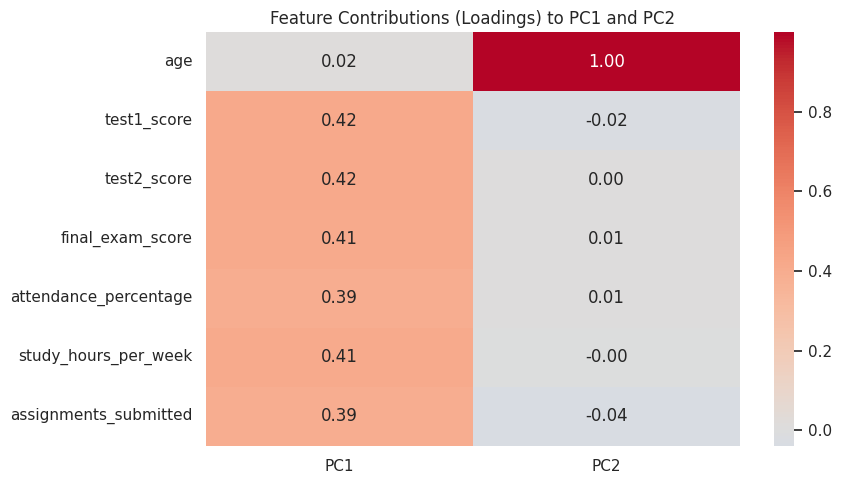

In [14]:
loadings = pd.DataFrame(
    pca_full.components_.T,
    columns=[f"PC{i}" for i in range(1, len(feature_columns) + 1)],
    index=feature_columns
)

print("Feature loadings for the first two principal components:")
display(loadings[["PC1", "PC2"]].round(3))

plt.figure(figsize=(9, 5))
sns.heatmap(loadings[["PC1", "PC2"]], annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Feature Contributions (Loadings) to PC1 and PC2")
plt.tight_layout()
plt.show()

## 13. Compare Original and Reduced Dimensions

The following output summarises the reduction achieved by PCA.

In [15]:
summary = pd.DataFrame({
    "Measure": ["Original dimensions", "Reduced dimensions", "Variance retained"],
    "Value": [X_scaled.shape[1], n_components_95, f"{cumulative_variance[n_components_95 - 1]:.2%}"]
})
display(summary)

,Measure,Value
0,Original dimensions,7
1,Reduced dimensions,5
2,Variance retained,95.04%


## Result

PCA was successfully applied to the standardized Student Performance dataset. The original numerical features were transformed into a smaller set of principal components while retaining at least 95% of the total variance. The two-dimensional plot and loading table help interpret the dominant patterns in student performance.

## Viva Questions

1. Why is feature scaling important before PCA?
2. Is PCA supervised or unsupervised? Why?
3. What does explained variance mean?
4. What is the difference between PC1 and PC2?
5. Why are identifier columns excluded from PCA?
6. Does PCA select original features or create new features?
7. What may be lost when the number of components is reduced?
8. Why should `pass_fail` not be included as an input feature for PCA in this experiment?